# 09 · Independent validation against LVIS 2019 (regions never used for development)

**Question:** do the reclassified 30 m heights hold up **outside** the Alaska development sites (interior G-LiHT tiles 3457,
3553, Kenai 3836, 3928, Seward transects), across boreal and Arctic regions of Alaska and western Canada?

**Why LVIS 2019:** NASA's airborne LVIS laser flew ~1,700 ABoVE flight segments in summer 2019, the same summers ICESat-2
was collecting, so trees and shrubs have not grown or been cut between the two. The gridded 30 m product
(`ABoVE_LVIS_VegetationStructure_1923`, ORNL DAAC; local copies on ADAPT) gives, for each 30 m cell, the mean LVIS relative
heights RH10–RH100 and the number of LVIS shots.

**Why this is a real test:** nothing in configs v0.1–v0.3 was chosen using these regions. Settings that were chosen from the
development sites (e.g. the column-test settings) are judged here; any setting chosen *here* (the v0.3 `top_k`) is reported
region by region, so a choice that only works in one region is visible.

**Reference height of a segment:** mean LVIS RH98 along the segment's centre line (11 points, first to last photon), i.e.
the 30 m cells the footprint crosses, weighted by length. LVIS RH comes from a return waveform: over bare ground it reads
about 0.5–1 m, not 0, so in the shortest class a small positive ICESat-2 minus LVIS difference is expected even when right.

**Versions compared (all from the same ATL03 v007 photons):** current v7 30 m (ATL08 classes → PhoREAL), ATL08 classes →
our 30 m (check), reclassified photons → our 30 m with **config v0.2** and with **config v0.3**.

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.3.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
CFGS = {"v0.2": ipl.load_config(REPO / "config" / "atl03_reclass_v0.2.yaml"), "v0.3": cfg}
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
LV = WORK / "lvis"; (LV / "photons").mkdir(parents=True, exist_ok=True)               # fetched photons per LVIS segment (shared)
OUT = RUN / "validation_lvis"; OUT.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| configs", {k: c["config_sha1"] for k, c in CFGS.items()}, "| run_dir:", RUN)

profile: adapt | configs {'v0.2': 'fc2468cc8841', 'v0.3': '9a8813268163'} | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.3


## 1 · Which LVIS flight segments, in which regions

**Input:** the ORNL index of LVIS 2019 flight segments (one polygon per segment) and the boreal tile grid.

**What happens:** keep ABoVE 2019 segments (the GEDI 2019 campaign flew south of 37° N) that overlap boreal tiles and do
**not** touch the four development tiles; give each a region by its longitude and latitude; pick `N_PER_REGION` segments
per region at random (fixed seed) among those of at least `MIN_AREA_KM2`, so sites are spread out rather than hand-picked.

**Output:** `validation_lvis/selected_segments.parquet` and a map.

In [2]:
N_PER_REGION = 8          # LVIS flight segments per region
MIN_AREA_KM2 = 10         # skip small fragments
DEV_TILES = {3457, 3553, 3836, 3928}
ICESAT2_YEARS = [2019]    # same summer as the LVIS flights

def region_of(lon, lat):
    if lon < -141:
        return "Alaska Arctic" if lat >= 66.0 else "Alaska boreal"
    if lon < -124:
        return "Yukon / N BC"
    if lon < -110:
        return "NWT"
    return "Prairies / Shield"

idx = gpd.read_file(LV / "LVIS_ABoVE_spatial_footprints_2017_2019.gpkg", layer="LVISF3_2019")
idx["stem"] = idx.FILE.str.replace("_lvis_pt_cnt_30m.tif", "", regex=False)
idx = idx[idx.stem.str.contains("ABoVE2019")].copy()
idx["area_km2"] = idx.to_crs(3338).area / 1e6
c = idx.to_crs(4326).geometry.representative_point()
idx["lon"], idx["lat"] = c.x.values, c.y.values
idx["region"] = [region_of(a, b) for a, b in zip(idx.lon, idx.lat)]
tiles = gpd.read_file(cfg["paths"]["boreal_tiles"])
j = gpd.sjoin(idx[["stem", "geometry"]].to_crs(tiles.crs), tiles[["tile_num", "geometry"]], predicate="intersects")
in_boreal = set(j.stem)
touches_dev = set(j[j.tile_num.isin(DEV_TILES)].stem)
cand = idx[idx.stem.isin(in_boreal - touches_dev) & (idx.area_km2 >= MIN_AREA_KM2)]
sel = pd.concat([g.sample(min(N_PER_REGION, len(g)), random_state=0) for _, g in cand.groupby("region")])
sel = sel.assign(has_rasters=[os.path.exists(ref.lvis_paths(s, 2019)["RH098_mean"]) for s in sel.stem])
sel.to_parquet(OUT / "selected_segments.parquet")
print(f"{len(idx)} ABoVE 2019 segments; {len(in_boreal)} overlap boreal tiles; {len(touches_dev)} touch development tiles")
sel.groupby("region").agg(segments=("stem", "size"), area_km2=("area_km2", "sum"), rasters=("has_rasters", "sum")).round(0)

1740 ABoVE 2019 segments; 1579 overlap boreal tiles; 66 touch development tiles


,segments,area_km2,rasters
region,,,
Alaska Arctic,8,414.0,8
Alaska boreal,8,415.0,8
NWT,8,434.0,8
Prairies / Shield,8,429.0,8
Yukon / N BC,8,420.0,8


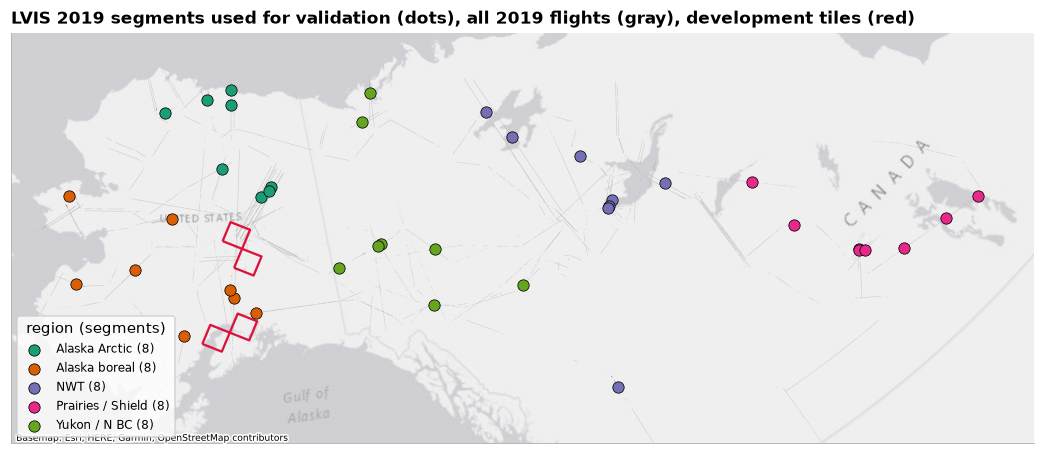

In [3]:
# Map: selected LVIS 2019 segments by region (Alaska Albers, ESRI Light Gray basemap); dots mark the selected segments
AK = 3338
REGION_COLORS = dict(zip(sorted(sel.region.unique()), ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e"]))
fig, ax = plt.subplots(figsize=(12, 6.5))
idx.to_crs(AK).plot(ax=ax, color="0.7", lw=0, alpha=0.6, zorder=2)
for reg, g in sel.groupby("region"):
    g2 = g.to_crs(AK)
    g2.plot(ax=ax, color=REGION_COLORS[reg], lw=0, zorder=3)
    c = g2.geometry.representative_point()
    ax.scatter(c.x, c.y, s=55, color=REGION_COLORS[reg], edgecolor="k", lw=0.5, zorder=5, label=f"{reg} ({len(g)})")
tiles[tiles.tile_num.isin(DEV_TILES)].to_crs(AK).boundary.plot(ax=ax, color="crimson", lw=1.5, zorder=4)
xmin, ymin, xmax, ymax = sel.to_crs(AK).total_bounds
pad = 0.06 * max(xmax - xmin, ymax - ymin)
ax.set_xlim(xmin - pad, xmax + pad); ax.set_ylim(ymin - pad, ymax + pad)
ps.add_basemap(ax, AK); ps.map_axes(ax, "LVIS 2019 segments used for validation (dots), all 2019 flights (gray), development tiles (red)")
ax.legend(loc="lower left", frameon=True, title="region (segments)")
fig.savefig(FIG / "09_lvis_selection_map.png")

## 2 · Fetch every ICESat-2 photon over each selected LVIS segment

**Input:** the selected segments.

**What happens:** for each LVIS segment, the ATL03 v007 granules of June–September 2019 crossing it are looked up in CMR,
and SlideRule returns every photon inside the segment's polygon (signal and solar background, with ATL08 v007 classes),
plus the current v7 30 m segments from PhoREAL (as in our training files). Photons are saved per LVIS segment in the shared
work folder, so later config versions reuse them.

**Output:** `lvis/photons/<segment>.parquet`, `lvis/photons/<segment>_phoreal.parquet`, and a fetch log.

In [4]:
sliderule = ipl.sliderule_init()
log = []
for r in sel.itertuples():
    fn, fpr = LV / "photons" / f"{r.stem}.parquet", LV / "photons" / f"{r.stem}_phoreal.parquet"
    if fn.exists():
        log.append({"stem": r.stem, "status": "cached"}); continue
    aoi = gpd.GeoSeries([r.geometry], crs=idx.crs).to_crs(4326).iloc[0].buffer(0)
    aoi = aoi.simplify(0.0005)
    try:
        grs = ipl.granules_from_cmr(aoi, ICESAT2_YEARS, cfg["icesat2"]["months"], release=cfg["icesat2"]["release"])
        if not grs:
            log.append({"stem": r.stem, "status": "no granules"}); continue
        ph = ipl.fetch_photons(aoi, grs, cfg)
        if not len(ph):
            log.append({"stem": r.stem, "status": "no photons", "granules": len(grs)}); continue
        ph = ph.assign(lvis_stem=r.stem, region=r.region)
        ipl.write_parquet(ph, fn, ipl.provenance(cfg, lvis_stem=r.stem, granules=grs))
        pr = ipl.fetch_phoreal(aoi, grs, cfg)
        if len(pr):
            ipl.write_parquet(pr, fpr, ipl.provenance(cfg, lvis_stem=r.stem))
        log.append({"stem": r.stem, "status": "fetched", "granules": len(grs), "photons": len(ph), "tracks": ph.track_id.nunique()})
    except Exception as e:
        log.append({"stem": r.stem, "status": f"error: {type(e).__name__}: {str(e)[:120]}"})
log = pd.DataFrame(log); log.to_csv(OUT / "fetch_log.csv", index=False)
log.status.str.split(":").str[0].value_counts()

status
cached    40
Name: count, dtype: int64

## 3 · Classify, build 30 m segments for each version, attach the LVIS reference height

**What happens, per LVIS segment:**
1. The same photons are classified three ways: ATL08 v007 classes (as delivered), and our reclassifier with config v0.2 and
   with config v0.3.
2. 30 m segments are built from each (`segment_metrics`, same 30 m grid along track, so the versions line up segment by
   segment); the current v7 30 m PhoREAL segments are matched to the nearest segment on the same track.
3. Each segment gets the LVIS reference heights (RH95, RH98, RH100 and shots per cell) along its centre line.

**Output:** `validation_lvis/segments_lvis.parquet` (one row per segment, columns per version).

In [5]:
def build_segments(stem, region):
    """All versions' 30 m segments from the photons over one LVIS segment (val.segments_all_versions), plus LVIS RH."""
    ph = gpd.read_parquet(LV / "photons" / f"{stem}.parquet")
    fpr = LV / "photons" / f"{stem}_phoreal.parquet"
    base = val.segments_all_versions(ph, CFGS, cfg, gpd.read_parquet(fpr) if fpr.exists() else None)
    if not len(base):
        return None
    return ref.lvis_segment_metrics(base, stem, 2019).assign(region=region)

fn = OUT / "segments_lvis.parquet"
if fn.exists():
    segs = gpd.read_parquet(fn)
else:
    parts = []
    for r in sel.itertuples():
        if (LV / "photons" / f"{r.stem}.parquet").exists():
            try:
                b = build_segments(r.stem, r.region)
                if b is not None:
                    parts.append(b)
            except Exception as e:
                print(r.stem, "failed:", type(e).__name__, str(e)[:150])
    segs = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=4326)
    ipl.write_parquet(segs, fn, ipl.provenance(cfg, configs={k: c["config_sha1"] for k, c in CFGS.items()}))
segs = segs[segs.lvis_n >= 6]            # at least half the centre-line points on valid LVIS cells
segs["light"] = np.where(segs.solar_elevation > 0, "day", "night")
segs["beam"] = np.where(segs.strong, "strong", "weak")
segs.groupby("region").agg(segments=("seg", "size"), lvis_segments=("lvis_stem", "nunique"),
                           lvis_rh98_median=("lvis_RH098_mean", "median"), day_share=("light", lambda s: (s == "day").mean())).round(2)

,segments,lvis_segments,lvis_rh98_median,day_share
region,,,,
Alaska Arctic,10082,8,0.63,0.85
Alaska boreal,4101,7,1.48,0.70
NWT,9784,8,4.30,0.63
Prairies / Shield,5396,8,5.25,0.61
Yukon / N BC,6506,8,4.38,0.61


## 4 · Results by reference height class and region

Mean bias and RMSE of each version against LVIS RH98, per LVIS height class, for each region and all regions together.
**Coverage** = share of segments for which a version reports a height. **Common segments** = segments every version reports,
so differences between versions are not due to different sets of segments.

coverage (share of segments with a height)


,current v7 30 m,ATL08 classes → our 30 m (check),v0.2,v0.3
region,,,,
Alaska Arctic,0.88,0.55,0.66,0.65
Alaska boreal,0.82,0.72,0.62,0.62
NWT,0.95,0.85,0.62,0.61
Prairies / Shield,0.87,0.73,0.64,0.63
Yukon / N BC,0.89,0.75,0.62,0.62


bias  \
version                             ATL08 classes → our 30 m (check)   
region            height_class                                         
Alaska Arctic     0-1 m                                         6.51   
                  1-2 m                                         4.82   
                  10-15 m                                      -0.91   
                  15-20 m                                      -1.19   
                  2-5 m                                         3.75   
                  20+ m                                          NaN   
                  5-10 m                                        0.59   
                  all                                           4.72   
                  spurious_veg_rate                             0.68   
Alaska boreal     0-1 m                                         7.80   
                  1-2 m                                         5.41   
                  10-15 m                                       3.93   
                  15-20 m                                       7.41   
                  2-5 m                                         4.73   
                  20+ m                                         3.75   
                  5-10 m                                        3.69   
                  all                                           5.99   
                  spurious_veg_rate                             0.68   
NWT               0-1 m                                         2.00   
                  1-2 m                                         2.44   
                  10-15 m                                       0.79   
                  15-20 m                                       0.79   
                  2-5 m                                         2.49   
                  20+ m                                         1.20   
                  5-10 m                                        1.45   
                  all                                           1.78   
                  spurious_veg_rate                             0.42   
Prairies / Shield 0-1 m                                         1.34   
                  1-2 m                                         2.04   
                  10-15 m                                       1.15   
                  15-20 m                                       0.60   
                  2-5 m                                         1.67   
                  20+ m                                         1.35   
                  5-10 m                                        1.64   
                  all                                           1.51   
                  spurious_veg_rate                             0.37   
Yukon / N BC      0-1 m                                         2.61   
                  1-2 m                                         3.94   
                  10-15 m                                       2.16   
                  15-20 m                                      -0.10   
                  2-5 m                                         3.05   
                  20+ m                                         0.83   
                  5-10 m                                        3.16   
                  all                                           2.78   
                  spurious_veg_rate                             0.33   
all regions       0-1 m                                         5.46   
                  1-2 m                                         3.80   
                  10-15 m                                       1.12   
                  15-20 m                                       0.56   
                  2-5 m                                         2.86   
                  20+ m                                         1.58   
                  5-10 m                                        1.83   
                  all                                           3.06   
                  spurious_veg_r

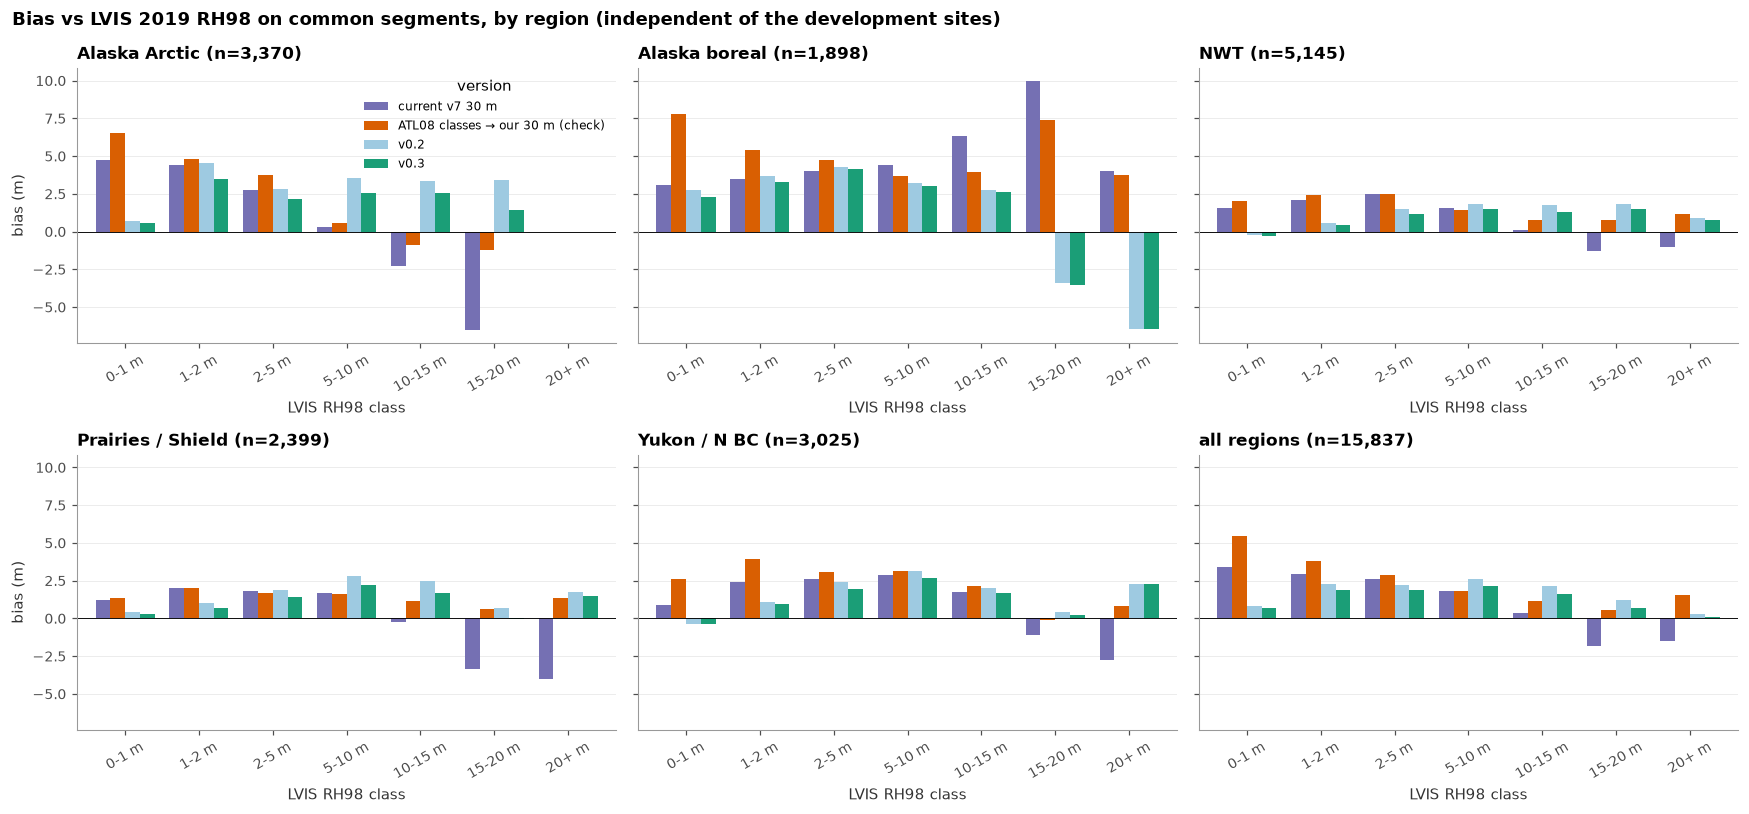

In [6]:
VERS = {"current v7 30 m": "h_canopy_phoreal", "ATL08 classes → our 30 m (check)": "h_canopy_atl08",
        "v0.2": "h_canopy_v02", "v0.3": "h_canopy_v03"}
VCOL = {"current v7 30 m": val.SCHEME_COLORS[val.LABEL_CURRENT], "ATL08 classes → our 30 m (check)": val.SCHEME_COLORS[val.LABEL_CHECK],
        "v0.2": "#9ecae1", "v0.3": val.SCHEME_COLORS[val.LABEL_NEW]}
REF = "lvis_RH098_mean"
edges = cfg["validation"]["height_classes_m"]
cov = pd.DataFrame({k: segs.groupby("region")[c].apply(lambda s: s.notna().mean()) for k, c in VERS.items()}).round(2)
print("coverage (share of segments with a height)"); display(cov)
common = segs.dropna(subset=list(VERS.values()) + [REF])
rows = []
for reg, g in list(common.groupby("region")) + [("all regions", common)]:
    for k, c in VERS.items():
        rows.append(val.metrics_by_height_class(g[c], g[REF], edges, cfg["validation"]["spurious_veg"]).assign(region=reg, version=k))
res = pd.concat(rows).reset_index(names="height_class")
res.to_csv(OUT / "lvis_by_class_region_common.csv", index=False)
regions = sorted(common.region.unique()) + ["all regions"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharey=True)
for ax, reg in zip(axes.ravel(), regions):
    tt = res[(res.region == reg) & ~res.height_class.isin(["all", "spurious_veg_rate"])]
    pv = tt.pivot(index="height_class", columns="version", values="bias").reindex(val.height_class_labels(edges))[list(VERS)]
    pv.plot.bar(ax=ax, rot=30, width=0.8, color=[VCOL[c] for c in pv.columns], legend=(reg == regions[0]))
    ax.axhline(0, c="k", lw=0.6); ax.grid(axis="x", visible=False)
    ax.set_title(f"{reg} (n={int((common.region == reg).sum()) if reg != 'all regions' else len(common):,})"); ax.set_xlabel("LVIS RH98 class"); ax.set_ylabel("bias (m)")
for ax in axes.ravel()[len(regions):]:
    ax.axis("off")
fig.suptitle("Bias vs LVIS 2019 RH98 on common segments, by region (independent of the development sites)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "09_lvis_bias_by_region.png")
res.pivot_table(index=["region", "height_class"], columns="version", values=["n", "bias", "rmse"]).round(2)

### Tall-forest acceptance and spurious vegetation, per region
Acceptance criterion (LOG, 15 Oct): in every LVIS class ≥ 10 m and every region, a version's bias must be no more negative
than the current v7 30 m. Spurious vegetation: LVIS RH98 < 1 m but ICESat-2 > 2 m (share of those segments).

In [7]:
tall = [c for c in val.height_class_labels(edges) if int(c.split("-")[0].split("+")[0]) >= 10]
acc = []
for reg in sorted(common.region.unique()):
    for cl in tall:
        t = res[(res.region == reg) & (res.height_class == cl)].set_index("version")
        if t.empty or t.loc["current v7 30 m", "n"] < 10:
            continue
        b7 = t.loc["current v7 30 m", "bias"]
        acc.append({"region": reg, "class": cl, "n": int(t.loc["v0.3", "n"]), "bias current v7": b7,
                    **{f"{v} passes": bool(t.loc[v, "bias"] >= b7) for v in ("v0.2", "v0.3")},
                    **{f"bias {v}": t.loc[v, "bias"] for v in ("v0.2", "v0.3")}})
acc = pd.DataFrame(acc); acc.to_csv(OUT / "lvis_tall_acceptance.csv", index=False)
spur = res[res.height_class == "spurious_veg_rate"].pivot(index="region", columns="version", values="bias")[list(VERS)].round(3)
display(spur.rename_axis(None, axis=1))
acc.round(2)

,current v7 30 m,ATL08 classes → our 30 m (check),v0.2,v0.3
region,,,,
Alaska Arctic,0.504,0.676,0.095,0.088
Alaska boreal,0.574,0.685,0.299,0.285
NWT,0.399,0.415,0.081,0.071
Prairies / Shield,0.402,0.367,0.107,0.089
Yukon / N BC,0.233,0.330,0.072,0.072
all regions,0.468,0.589,0.130,0.122


,region,class,n,bias current v7,v0.2 passes,v0.3 passes,bias v0.2,bias v0.3
0,Alaska Arctic,10-15 m,198,-2.24,True,True,3.38,2.54
1,Alaska Arctic,15-20 m,25,-6.53,True,True,3.44,1.45
2,Alaska boreal,10-15 m,33,6.33,False,False,2.77,2.59
3,Alaska boreal,15-20 m,10,10.01,False,False,-3.39,-3.51
4,Alaska boreal,20+ m,14,4.02,False,False,-6.44,-6.44
5,NWT,10-15 m,844,0.11,True,True,1.76,1.33
6,NWT,15-20 m,294,-1.31,True,True,1.85,1.51
7,NWT,20+ m,45,-0.99,True,True,0.88,0.75
8,Prairies / Shield,10-15 m,379,-0.22,True,True,2.46,1.72
9,Prairies / Shield,15-20 m,174,-3.33,True,True,0.68,-0.05


## 5 · By signal: day/night × beam strength, and which LVIS percentile each version tracks

In [8]:
common = common.assign(signal_stratum=common.light + " · " + common.beam)
rows = []
for st, g in common.groupby("signal_stratum"):
    for k, c in VERS.items():
        e = g[c] - g[REF]
        rows.append({"stratum": st, "version": k, "n": len(g), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()), "r": g[[c, REF]].corr().iat[0, 1]})
sig = pd.DataFrame(rows); sig.to_csv(OUT / "lvis_by_signal.csv", index=False)
rows = []
for k, c in VERS.items():
    for p in ("RH095_mean", "RH098_mean", "RH100_mean"):
        d = common[[c, f"lvis_{p}"]].dropna(); e = d[c] - d[f"lvis_{p}"]
        rows.append({"version": k, "LVIS": p[:5], "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()), "r": d.corr().iat[0, 1]})
display(pd.DataFrame(rows).pivot(index="LVIS", columns="version", values=["bias", "rmse", "r"]).round(2))
sig.pivot(index="stratum", columns="version", values=["n", "r", "bias", "rmse"]).round(2)

bias                              \
version ATL08 classes → our 30 m (check) current v7 30 m  v0.2  v0.3   
LVIS                                                                   
RH095                               3.81            2.93  2.68  2.31   
RH098                               3.06            2.18  1.93  1.56   
RH100                               1.71            0.83  0.58  0.20   

                                    rmse                              \
version ATL08 classes → our 30 m (check) current v7 30 m  v0.2  v0.3   
LVIS                                                                   
RH095                               7.40            6.93  6.54  6.01   
RH098                               7.13            6.71  6.25  5.74   
RH100                               6.74            6.49  6.01  5.58   

                                       r                              
version ATL08 classes → our 30 m (check) current v7 30 m  v0.2  v0.3  
LVIS                                                                  
RH095                               0.49            0.50  0.64  0.66  
RH098                               0.48            0.49  0.64  0.66  
RH100                               0.47            0.49  0.64  0.66

n                          \
version        ATL08 classes → our 30 m (check) current v7 30 m    v0.2   
stratum                                                                   
day · strong                             8413.0          8413.0  8413.0   
day · weak                               2424.0          2424.0  2424.0   
night · strong                           4327.0          4327.0  4327.0   
night · weak                              673.0           673.0   673.0   

                                                      r                        \
version           v0.3 ATL08 classes → our 30 m (check) current v7 30 m  v0.2   
stratum                                                                         
day · strong    8413.0                             0.58            0.57  0.64   
day · weak      2424.0                             0.20            0.28  0.47   
night · strong  4327.0                             0.36            0.38  0.64   
night · weak     673.0                             0.57            0.65  0.73   

                                                 bias                        \
version         v0.3 ATL08 classes → our 30 m (check) current v7 30 m  v0.2   
stratum                                                                       
day · strong    0.66                             2.70            1.21  2.81   
day · weak      0.50                             3.61            1.13 -0.40   
night · strong  0.64                             3.72            4.75  2.02   
night · weak    0.73                             1.28            1.52 -1.24   

                                                 rmse                        \
version         v0.3 ATL08 classes → our 30 m (check) current v7 30 m  v0.2   
stratum                                                                       
day · strong    2.17                             5.59            4.45  6.85   
day · weak     -0.62                             6.35            4.34  4.56   
night · strong  2.02                             9.91           10.59  6.14   
night · weak   -1.24                             5.31            4.83  3.83   

                      
version         v0.3  
stratum               
day · strong    6.05  
day · weak      4.13  
night · strong  6.14  
night · weak    3.83

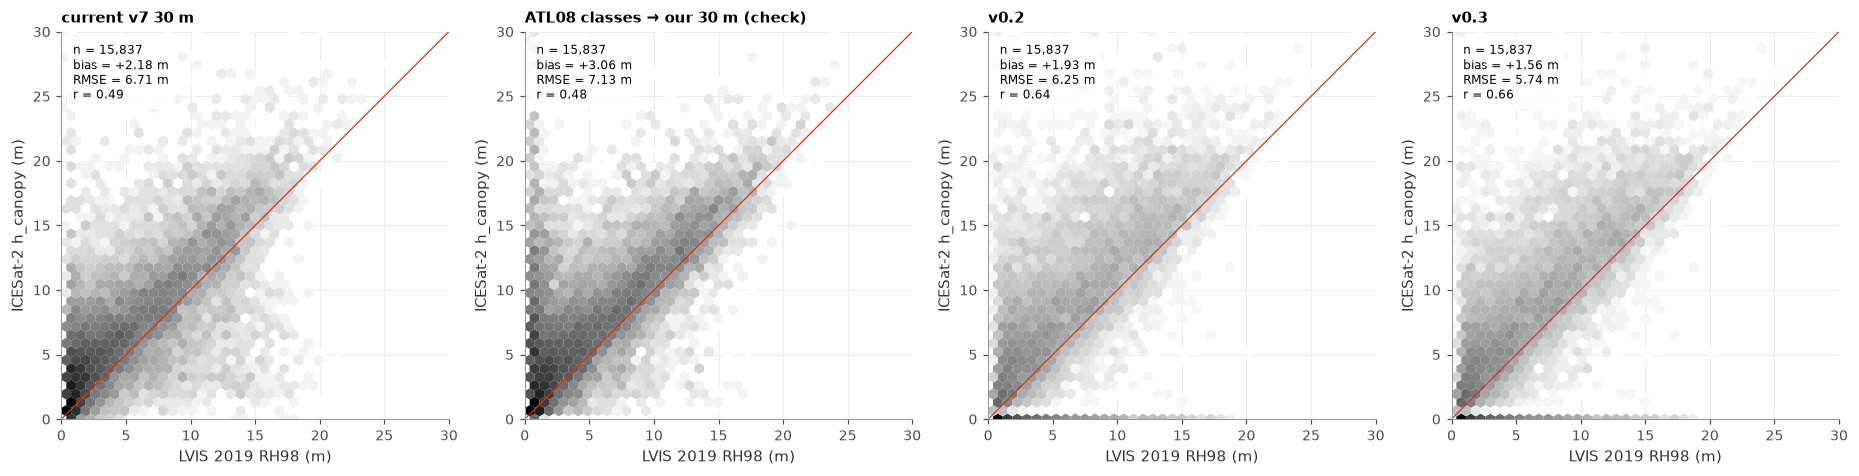

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
for ax, (k, c) in zip(axes, VERS.items()):
    val.plot_scatter(ax, common[c], common[REF], k, lim=30)
    ax.set_xlabel("LVIS 2019 RH98 (m)")
fig.tight_layout(); fig.savefig(FIG / "09_lvis_scatter.png")

## Results
Summarise after review: per region, whether v0.3 meets the tall-forest acceptance criterion and reduces spurious
vegetation; whether the v0.3 column-top rule (chosen on development data) helps or hurts in every independent region; how
results differ by day/night and beam; which LVIS percentile ICESat-2 heights track.